In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt 

from tqdm import tqdm
from model import ExponentialRepresentation
from scipy.stats import binned_statistic_2d

import utils

In [2]:
# Load model parameters
sigma_A = torch.load("./parameters/sigma_A_pc.pt", weights_only=True)
sigma_B = torch.load("./parameters/sigma_B_pc.pt", weights_only=True)
R = utils.random_orthogonal_matrix(len(sigma_A))

p0 = utils.starting_state(R)
p0 = p0.to(torch.float32)

A = R.T@sigma_A@R 
B = R.T@sigma_B@R

model = ExponentialRepresentation(A, B)
print(f"Number of units: {len(A)}")

Number of units: 120


In [3]:
batch_size = 50 # number of spatial samples
batches = 500
arena_size = 1.5
r_batch = [arena_size*(2*torch.rand((batch_size, 2)).to(torch.float32) - 1) for i in range(batches)]

p_ = utils.batch_inference(model, r_batch, p0)
r = np.concatenate(r_batch)

100%|██████████| 500/500 [00:05<00:00, 88.08it/s]


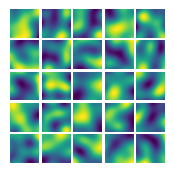

In [4]:
if rect:= False: # rectify or nay
    p = rectify(p_)
else:
    p = p_

ratemaps = utils.compute_ratemaps(r[:,0], r[:,1], p, bins = 32)
utils.ratemap_collage(ratemaps, 5, 5, figsize = (2,2))
plt.savefig("./figures/pc_ratemaps.svg", dpi=300, transparent = True, bbox_inches = "tight")

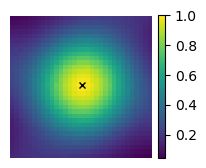

In [5]:
# plot correlation between vector at [a,a] and all other pop. vecs.
plt.figure(figsize=(2,2))
a = 16
prod = np.nansum(ratemaps[:,a, a, None,None]*ratemaps, axis = 0)
plt.imshow(prod.T, vmax = 1, extent= (-arena_size, arena_size, -arena_size, arena_size), origin='lower')
plt.plot(1/32, 1/32, "kx", markersize = 5)
plt.colorbar(fraction =0.046, pad=0.04)
plt.axis("off")
plt.savefig("./figures/pc_similarity.svg", dpi=300, transparent = True, bbox_inches = "tight")